<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Energy example: -12.147213205333742
Reconstruction error: 0.12684703873403216


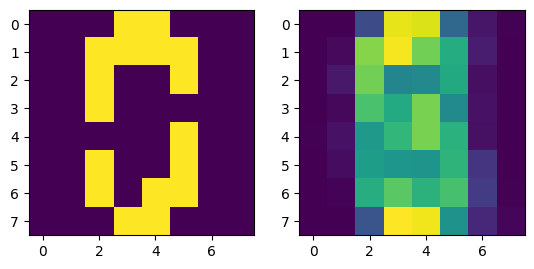

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from scipy.special import expit
X=load_digits().data/16; X=(X>.5).astype(float)[:1000]; n,v=X.shape; h=64; rng=np.random.default_rng(25); W=rng.normal(0,.01,(v,h)); a=np.zeros(v); b=np.zeros(h)
def sample(p): return (rng.random(p.shape)<p).astype(float)
for epoch in range(10):
 for batch in np.array_split(X,20):
  ph=expit(batch@W+b); h0=sample(ph); pv=expit(h0@W.T+a); v1=sample(pv); ph1=expit(v1@W+b)
  W+=.01*(batch.T@ph-v1.T@ph1)/len(batch); a+=.01*(batch-v1).mean(0); b+=.01*(ph-ph1).mean(0)
print('Energy example:',-a@X[0]-b@h0[0]-X[0]@W@h0[0])
recon=expit(expit(X@W+b)@W.T+a); print('Reconstruction error:',np.mean((X-recon)**2))
fig,ax=plt.subplots(1,2); ax[0].imshow(X[0].reshape(8,8)); ax[1].imshow(recon[0].reshape(8,8)); plt.show()